In [2]:
import pandas as pd
from zipfile import ZipFile

zip_path = "/Users/rachit/Code/smart-study-planner/data/raw/ednet/EdNet-KT1.zip"

with ZipFile(zip_path) as archive:
    with archive.open("KT1/u246317.csv") as file:
        student_data = pd.read_csv(file)

student_data.head()

,timestamp,solving_id,question_id,user_answer,elapsed_time
0,1535196434651,1,q8098,b,20000
1,1535196459648,2,q8074,c,22000
2,1535196482553,3,q176,b,21000
3,1564677167247,4,q1279,c,17000
4,1564677196590,5,q6363,d,27000


In [3]:
student_data.shape

(30, 5)

In [6]:
contents_zip_path = "/Users/rachit/Code/smart-study-planner/data/raw/ednet/EdNet-Contents.zip"


with ZipFile(contents_zip_path) as archive:
    question_info = pd.read_csv(archive.open("contents/questions.csv"))

student_enriched = student_data.merge(
    question_info[["question_id", "correct_answer", "part", "bundle_id"]],
    on="question_id",
    how="left",
    validate="many_to_one",
)

student_enriched["is_correct"] = (
    student_enriched["user_answer"] == student_enriched["correct_answer"]
)

student_enriched[
    ["question_id", "user_answer", "correct_answer", "is_correct", "part", "bundle_id"]
].head(10)

,question_id,user_answer,correct_answer,is_correct,part,bundle_id
0,q8098,b,b,True,1,b5569
1,q8074,c,c,True,1,b5545
2,q176,b,d,False,1,b176
3,q1279,c,c,True,2,b1279
4,q6363,d,d,True,5,b4895
5,q3670,c,c,True,5,b2202
6,q3788,b,d,False,5,b2320
7,q3815,b,d,False,5,b2347
8,q6119,c,c,True,5,b4651
9,q5019,a,a,True,5,b3551


In [7]:
student_enriched.groupby("part").agg(
    questions = ("question_id", "count"),
    correct=("is_correct", "sum"),
    accuracy=("is_correct", "mean"),
    median_time_ms = ("elapsed_time", "median"),
).round(2)

,questions,correct,accuracy,median_time_ms
part,,,,
1,3,2,0.67,21000.0
2,10,8,0.80,17500.0
5,17,9,0.53,27000.0


In [9]:
student_enriched.assign(
    elapsed_seconds = student_enriched["elapsed_time"]/1000
).groupby("is_correct").agg(
    questions =("question_id", "count"),
    median_seconds =("elapsed_seconds", "median"),
    mean_seconds=("elapsed_seconds", "mean"),
).round(1)

,questions,median_seconds,mean_seconds
is_correct,,,
False,11,22.0,29.3
True,19,20.0,20.7


In [10]:
with ZipFile(zip_path) as archive:
    student_files = [
        name for name in archive.namelist()
        if name.startswith("KT1/u") and name.endswith(".csv")
    ]

len(student_files)

784309

In [13]:
student_lengths = []

with ZipFile(zip_path) as archive:
    for name in student_files:
        with archive.open(name) as file:
            student_lengths.append(sum(1 for _ in file) - 1)

pd.Series(student_lengths, name = "questions_per_student").describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]
)

count    784309.000000
mean        121.500488
std         543.001374
min           1.000000
25%           7.000000
50%          11.000000
75%          39.000000
90%         193.000000
99%        2197.000000
max       40157.000000
Name: questions_per_student, dtype: float64

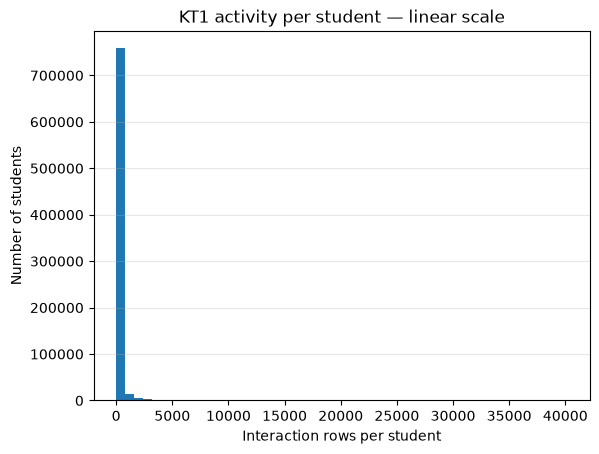

In [16]:
import matplotlib.pyplot as plt

plt.hist(student_lengths, bins=50)
plt.xlabel("Interaction rows per student")
plt.ylabel("Number of students")
plt.title("KT1 activity per student — linear scale")
plt.grid(axis="y", alpha=0.3)
plt.show()

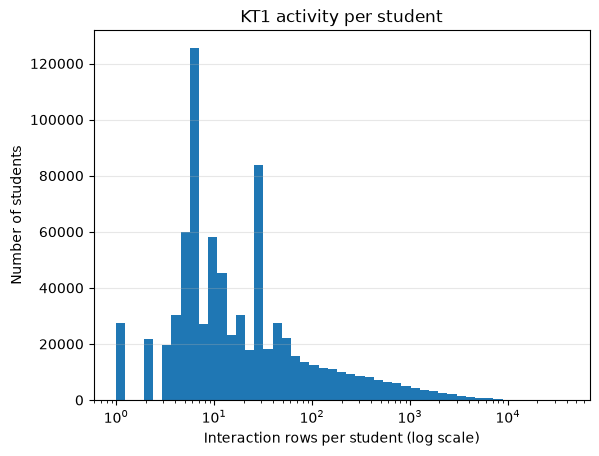

In [15]:
import numpy as np
import matplotlib.pyplot as plt

bins = np.logspace(0, np.log10(max(student_lengths)), 50)

plt.hist(student_lengths, bins = bins)
plt.xscale("log")
plt.xlabel("Interaction rows per student (log scale)")
plt.ylabel("Number of students")
plt.title("KT1 activity per student")
plt.grid(axis="y", alpha=0.3)
plt.show()

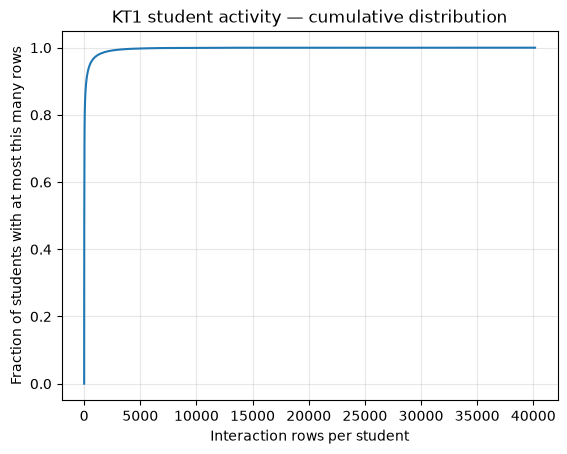

In [17]:
import numpy as np
import matplotlib.pyplot as plt

sorted_lengths = np.sort(student_lengths)
fraction_of_students = np.arange(1, len(sorted_lengths) + 1) / len(sorted_lengths)

plt.plot(sorted_lengths, fraction_of_students)
plt.xlabel("Interaction rows per student")
plt.ylabel("Fraction of students with at most this many rows")
plt.title("KT1 student activity — cumulative distribution")
plt.grid(alpha=0.3)
plt.show()

In [21]:
activity_summary = (
    activity_bands.value_counts()
    .reindex(activity_bands.categories, fill_value=0)
    .rename_axis("interaction rows per student")
    .to_frame("students")
)

activity_summary["percent"] = (
    activity_summary["students"] / len(student_lengths) * 100
).round(1)

activity_summary

,students,percent
interaction rows per student,,
1–11,395508,50.4
12–39,193222,24.6
40–193,117219,14.9
"194–2,197",70521,9.0
">2,197",7839,1.0


In [22]:
# For the same student sampled earlier:
student_data["question_id"].nunique(), len(student_data)

(30, 30)

In [23]:
from collections import Counter
from zipfile import ZipFile
import pandas as pd

unique_questions_per_student = []

with ZipFile(zip_path) as archive:
    for name in student_files:
        with archive.open(name) as f:
            questions = pd.read_csv(f, usecols=["question_id"])["question_id"]
            unique_questions_per_student.append(questions.nunique())

pd.Series(unique_questions_per_student, name="unique_questions_per_student").describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]
)

count    784309.000000
mean        101.911324
std         406.603117
min           1.000000
25%           7.000000
50%          10.000000
75%          37.000000
90%         170.000000
99%        1844.000000
max       11466.000000
Name: unique_questions_per_student, dtype: float64

In [24]:
repeat_rows_per_student = (
    pd.Series(student_lengths, name="total_rows")
    - pd.Series(unique_questions_per_student, name="unique_questions")
)

repeat_rows_per_student.describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]
)

count    784309.000000
mean         19.589163
std         184.425354
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
90%          16.000000
99%         389.000000
max       28815.000000
dtype: float64

In [25]:
(repeat_rows_per_student > 0).value_counts().rename(
    {False: "No repeated question IDs", True: "At least one repeated question ID"}
)

No repeated question IDs             593429
At least one repeated question ID    190880
Name: count, dtype: int64

In [26]:
question_info["part"].value_counts().sort_index()

part
1     643
2    1662
3    1266
4    1158
5    5703
6    1335
7    1402
Name: count, dtype: int64

In [27]:
part_summary = (
    student_enriched.groupby("part", observed=True)
    .agg(
        responses=("question_id", "size"),
        unique_questions=("question_id", "nunique"),
        correct=("is_correct", "sum"),
        accuracy=("is_correct", "mean"),
    )
)

part_summary["accuracy"] = (part_summary["accuracy"] * 100).round(1)
part_summary

,responses,unique_questions,correct,accuracy
part,,,,
1,3,3,2,66.7
2,10,10,8,80.0
5,17,17,9,52.9


In [28]:
from collections import defaultdict
from zipfile import ZipFile
import pandas as pd

# Look up each question's TOEIC part and correct answer
question_lookup = question_info.set_index("question_id")[["part", "correct_answer"]]

part_totals = defaultdict(lambda: {"responses": 0, "correct": 0})

with ZipFile(zip_path) as archive:
    for name in student_files:
        with archive.open(name) as f:
            answers = pd.read_csv(f, usecols=["question_id", "user_answer"])

        # Exclude blank answers from response and accuracy totals
        answers = answers.dropna(subset=["user_answer"])
        answers = answers[answers["user_answer"].astype(str).str.strip() != ""]

        # Attach part and correct answer to each response
        answers = answers.join(question_lookup, on="question_id")

        # Count answered questions and correct answers by part
        answers["is_correct"] = (
            answers["user_answer"].astype(str).str.strip().str.lower()
            == answers["correct_answer"].astype(str).str.strip().str.lower()
        )

        grouped = answers.groupby("part").agg(
            responses=("question_id", "size"),
            correct=("is_correct", "sum"),
        )

        for part, row in grouped.iterrows():
            part_totals[part]["responses"] += int(row["responses"])
            part_totals[part]["correct"] += int(row["correct"])

part_summary_all = pd.DataFrame.from_dict(part_totals, orient="index")
part_summary_all.index.name = "part"
part_summary_all = part_summary_all.sort_index()
part_summary_all["accuracy"] = (
    part_summary_all["correct"] / part_summary_all["responses"] * 100
).round(1)

part_summary_all

,responses,correct,accuracy
part,,,
1,7327998,5410039,73.8
2,17800711,12586482,70.7
3,8104719,5689255,70.2
4,7512397,4718812,62.8
5,40286608,24324744,60.4
6,9723645,6527451,67.1
7,4510202,2991899,66.3


In [29]:
part_summary_all["catalog_questions"] = question_info.groupby("part").size()
part_summary_all["catalog_share_%"] = (
    part_summary_all["catalog_questions"]
    / part_summary_all["catalog_questions"].sum()
    * 100
).round(1)

part_summary_all["response_share_%"] = (
    part_summary_all["responses"]
    / part_summary_all["responses"].sum()
    * 100
).round(1)

part_summary_all[
    ["catalog_questions", "catalog_share_%", "responses", "response_share_%", "accuracy"]
]

,catalog_questions,catalog_share_%,responses,response_share_%,accuracy
part,,,,,
1,643,4.9,7327998,7.7,73.8
2,1662,12.6,17800711,18.7,70.7
3,1266,9.6,8104719,8.5,70.2
4,1158,8.8,7512397,7.9,62.8
5,5703,43.3,40286608,42.3,60.4
6,1335,10.1,9723645,10.2,67.1
7,1402,10.6,4510202,4.7,66.3


In [30]:
part_summary_all["avg_responses_per_question"] = (
    part_summary_all["responses"] / part_summary_all["catalog_questions"]
).round(0).astype(int)

part_summary_all[["catalog_questions", "responses", "avg_responses_per_question"]]

,catalog_questions,responses,avg_responses_per_question
part,,,
1,643,7327998,11397
2,1662,17800711,10710
3,1266,8104719,6402
4,1158,7512397,6487
5,5703,40286608,7064
6,1335,9723645,7284
7,1402,4510202,3217


In [31]:
from collections import Counter

question_response_counts = Counter()

with ZipFile(zip_path) as archive:
    for name in student_files:
        with archive.open(name) as f:
            question_ids = pd.read_csv(f, usecols=["question_id"])["question_id"]

        question_response_counts.update(question_ids.value_counts().to_dict())

question_counts = question_info[["question_id", "part"]].copy()
question_counts["responses"] = (
    question_counts["question_id"].map(question_response_counts).fillna(0).astype(int)
)

print("All catalog questions:")
display(
    question_counts["responses"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99])
    .to_frame()
)
print("Questions with no responses:", (question_counts["responses"] == 0).sum())

print("Response-count distribution within each part:")
question_counts.groupby("part")["responses"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]
).round(0)

All catalog questions:


,responses
count,13169.000000
mean,7236.230997
std,11801.929592
min,0.000000
25%,2024.000000
50%,4627.000000
75%,8358.000000
90%,15341.800000
99%,44702.240000
max,241688.000000


Questions with no responses: 885
Response-count distribution within each part:


,count,mean,std,min,25%,50%,75%,90%,99%,max
part,,,,,,,,,,
1,643.0,11399.0,17694.0,0.0,5759.0,7179.0,11635.0,21486.0,46600.0,241688.0
2,1662.0,10712.0,13145.0,0.0,1197.0,9330.0,13653.0,21879.0,56297.0,209663.0
3,1266.0,6412.0,10074.0,0.0,3660.0,5532.0,7777.0,11807.0,16375.0,195679.0
4,1158.0,6490.0,15339.0,0.0,3257.0,4994.0,6377.0,9772.0,23902.0,183209.0
5,5703.0,7064.0,10648.0,0.0,2212.0,4399.0,7322.0,15828.0,47292.0,215507.0
6,1335.0,7286.0,9676.0,0.0,2326.0,4527.0,9320.0,17582.0,31314.0,105745.0
7,1402.0,3220.0,9200.0,0.0,488.0,1966.0,3873.0,6410.0,14474.0,165456.0


In [32]:
question_details = question_counts.merge(
    question_info[["question_id", "tags"]],
    on="question_id",
    how="left",
)

print("10 most-answered questions:")
display(
    question_details.nlargest(10, "responses")[
        ["question_id", "part", "responses", "tags"]
    ]
)

print("10 unanswered questions:")
display(
    question_details.loc[question_details["responses"] == 0, [
        "question_id", "part", "tags"
    ]].head(10)
)

10 most-answered questions:


,question_id,part,responses,tags
175,q176,1,241688,6;7;183
8073,q8074,1,240540,11;7;183
8097,q8098,1,239502,5;2;182
6184,q6185,5,215507,145
1278,q1279,2,209663,24;26;182;184
6242,q6243,5,207341,100
4177,q4178,5,201794,75
2068,q2069,3,195679,179;52;183;184
2067,q2068,3,195675,55;183;184
2066,q2067,3,195669,52;183;184


10 unanswered questions:


,question_id,part,tags
1424,q1425,3,53;185;183
1425,q1426,3,52;185;183
1426,q1427,3,54;185;183
2075,q2076,3,53;182;183
2076,q2077,3,53;182;183
2077,q2078,3,52;182;183
2096,q2097,3,56;182;183
2097,q2098,3,53;182;183
2098,q2099,3,55;182;183
2120,q2121,3,53;183;182


In [33]:
question_details.merge(
    question_info[["question_id", "bundle_id", "deployed_at"]],
    on="question_id",
    how="left",
).nlargest(10, "responses")[
    ["question_id", "part", "bundle_id", "deployed_at", "responses"]
]

,question_id,part,bundle_id,deployed_at,responses
175,q176,1,b176,1514559223800,241688
8073,q8074,1,b5545,1526633822552,240540
8097,q8098,1,b5569,1514559983093,239502
6184,q6185,5,b4717,1558092756175,215507
1278,q1279,2,b1279,1571281118714,209663
6242,q6243,5,b4775,1519099707759,207341
4177,q4178,5,b2710,1568688427404,201794
2068,q2069,3,b1623,1552357692671,195679
2067,q2068,3,b1623,1552357691490,195675
2066,q2067,3,b1623,1552357690338,195669


In [34]:
question_details.merge(
    question_info[["question_id", "bundle_id", "deployed_at"]],
    on="question_id",
    how="left",
).query("bundle_id == 'b1623'").sort_values("deployed_at")[
    ["question_id", "part", "bundle_id", "deployed_at", "responses"]
]

,question_id,part,bundle_id,deployed_at,responses
2066,q2067,3,b1623,1552357690338,195669
2067,q2068,3,b1623,1552357691490,195675
2068,q2069,3,b1623,1552357692671,195679


In [35]:
question_counts_with_bundle = question_counts.merge(
    question_info[["question_id", "bundle_id"]],
    on="question_id",
    how="left",
)

bundle_response_spread = question_counts_with_bundle.groupby("bundle_id")["responses"].agg(
    questions="size",
    lowest="min",
    highest="max",
)

bundle_response_spread["spread"] = (
    bundle_response_spread["highest"] - bundle_response_spread["lowest"]
)

bundle_response_spread.sort_values("questions", ascending=False).head(10)

,questions,lowest,highest,spread
bundle_id,,,,
b5439,5,0,0,0
b5316,5,6408,6414,6
b5351,5,4142,4143,1
b11265,5,0,0,0
b11266,5,0,0,0
b11276,5,0,0,0
b11277,5,0,0,0
b11278,5,0,0,0
b5335,5,6089,6094,5


In [36]:
answered_bundles = bundle_response_spread[
    bundle_response_spread["highest"] > 0
].copy()

answered_bundles["relative_spread"] = (
    answered_bundles["spread"] / answered_bundles["highest"]
)

print("Total bundles:", len(bundle_response_spread))
print("Bundles with no responses:", (bundle_response_spread["highest"] == 0).sum())
print(
    "Answered bundles where question counts differ by at most 1%:",
    (answered_bundles["relative_spread"] <= 0.01).mean().round(3),
)
print(
    "Answered bundles where every question has exactly the same count:",
    (answered_bundles["spread"] == 0).mean().round(3),
)

Total bundles: 9534
Bundles with no responses: 595
Answered bundles where question counts differ by at most 1%: 0.994
Answered bundles where every question has exactly the same count: 0.857


In [37]:
from collections import Counter

time_bins = Counter()
missing_times = 0
negative_times = 0

with ZipFile(zip_path) as archive:
    for name in student_files:
        with archive.open(name) as f:
            times = pd.read_csv(f, usecols=["elapsed_time"])["elapsed_time"]

        missing_times += int(times.isna().sum())
        negative_times += int((times < 0).sum())

        # Convert milliseconds to seconds, then count each time range
        seconds = times.dropna() / 1000
        ranges = pd.cut(
            seconds,
            bins=[-float("inf"), 0, 5, 30, 120, 600, float("inf")],
            labels=["<=0 sec", "0–5 sec", "5–30 sec", "30 sec–2 min",
                    "2–10 min", ">10 min"],
        )
        time_bins.update(ranges.value_counts().to_dict())

pd.Series(time_bins).rename("responses").to_frame()
print("Missing elapsed_time values:", missing_times)
print("Negative elapsed_time values:", negative_times)

Missing elapsed_time values: 0
Negative elapsed_time values: 0


In [38]:
pd.Series(time_bins).reindex(
    ["<=0 sec", "0–5 sec", "5–30 sec", "30 sec–2 min", "2–10 min", ">10 min"],
    fill_value=0,
).rename("responses").to_frame()

,responses
<=0 sec,258232
0–5 sec,3553561
5–30 sec,67759477
30 sec–2 min,23178975
2–10 min,522123
>10 min,21558


In [39]:
long_time_records = []

with ZipFile(zip_path) as archive:
    for name in student_files:
        with archive.open(name) as f:
            rows = pd.read_csv(
                f,
                usecols=["question_id", "solving_id", "user_answer", "elapsed_time"],
            )

        long_rows = rows[rows["elapsed_time"] > 600_000].copy()
        if not long_rows.empty:
            long_rows["student_id"] = name.rsplit("/", 1)[-1].removesuffix(".csv")
            long_time_records.append(long_rows)

long_time_df = pd.concat(long_time_records, ignore_index=True)

long_time_df.nlargest(20, "elapsed_time")[
    ["student_id", "question_id", "solving_id", "user_answer", "elapsed_time"]
]

,student_id,question_id,solving_id,user_answer,elapsed_time
632,u17507,q4040,2494,b,285924000
14237,u204041,q3412,6,a,283453667
14238,u204041,q3413,6,c,283453667
14239,u204041,q3411,6,b,283453667
10044,u20698,q8699,468,c,222855000
10384,u9410,q830,110,b,178208000
15834,u20633,q6493,1702,d,158745000
1715,u140244,q9520,42,c,133713000
4280,u76528,q760,100,b,109456000
14979,u496068,q5245,1,a,93681000


## Full EdNet EDA continuation

This section extends the KT1 question-response exploration to the higher-detail activity tiers and the rest of the Contents archive. Counts below come from full scans of the local ZIP archives. The tiers overlap: do not add their row totals together.

EdNet describes logs from Santa, a Korean TOEIC-preparation service. The official schema and tier descriptions are in the [EdNet README](https://github.com/riiid/ednet/blob/master/README.md).

### 1. What is in each tier?

Each KT file is one learner’s log. KT1 stores question responses. KT2–KT4 store progressively richer actions, so the same kinds of study activity appear at different levels of detail.

In [2]:
tier_inventory = pd.DataFrame([
    {"tier": "KT1", "student_files": 784_309, "records": 95_293_926,
     "grain": "Question-response rows"},
    {"tier": "KT2", "student_files": 297_444, "records": 56_360_602,
     "grain": "Question-solving actions"},
    {"tier": "KT3", "student_files": 297_915, "records": 89_270_654,
     "grain": "Question, explanation, and lecture actions"},
    {"tier": "KT4", "student_files": 297_915, "records": 131_441_538,
     "grain": "Full action stream, including media and purchase events"},
]).set_index("tier")

tier_inventory

,student_files,records,grain
tier,,,
KT1,784309,95293926,Question-response rows
KT2,297444,56360602,Question-solving actions
KT3,297915,89270654,"Question, explanation, and lecture actions"
KT4,297915,131441538,"Full action stream, including media and purcha..."


KT2 and KT3 were scanned across every student file for this EDA. All files within each tier had the same schema, and neither tier had an adjacent timestamp that moved backwards within a learner’s file. Blank `user_answer` values in these tiers occur on actions such as `enter`, `submit`, and `quit`, where no answer is expected.

The user populations overlap but are not identical: KT2 users are included in KT3, and KT3 users are included in KT4. KT4 has 7,562 user files that are absent from KT1. Treat tiers as related views, not independent datasets.

### 2. What actions does the richer log contain?

KT2–KT3 action counts below are from full archive scans. KT4 counts are from the earlier full scan of that archive.

In [3]:
tier_action_counts = pd.DataFrame({
    "KT2": {
        "enter": 16_488_061,
        "respond": 23_384_480,
        "submit": 16_488_061,
    },
    "KT3": {
        "enter": 32_943_087,
        "respond": 23_384_480,
        "submit": 16_488_061,
        "quit": 16_455_026,
    },
    "KT4": {
        "enter": 32_943_087,
        "respond": 23_384_480,
        "submit": 16_488_061,
        "quit": 16_455_026,
        "pause_audio": 16_879_046,
        "play_audio": 16_580_464,
        "erase_choice": 4_714_534,
        "play_video": 1_928_356,
        "pause_video": 1_898_080,
        "undo_erase_choice": 142_092,
        "pay": 26_583,
        "refund": 1_126,
        "enroll_coupon": 603,
    },
}).fillna(0).astype("int64")

tier_action_counts

,KT2,KT3,KT4
enter,16488061,32943087,32943087
respond,23384480,23384480,23384480
submit,16488061,16488061,16488061
quit,0,16455026,16455026
pause_audio,0,0,16879046
play_audio,0,0,16580464
erase_choice,0,0,4714534
play_video,0,0,1928356
pause_video,0,0,1898080
undo_erase_choice,0,0,142092


KT2 records repeated answer changes before submission, so a final answer and a sequence of tentative choices can be distinguished. KT3 adds explanation and lecture visits. KT4 adds audio/video controls, choice elimination, and account-payment events. These actions make KT2–KT4 much more useful than KT1 for describing *how* someone practiced, though they still do not prove that a particular activity caused learning.

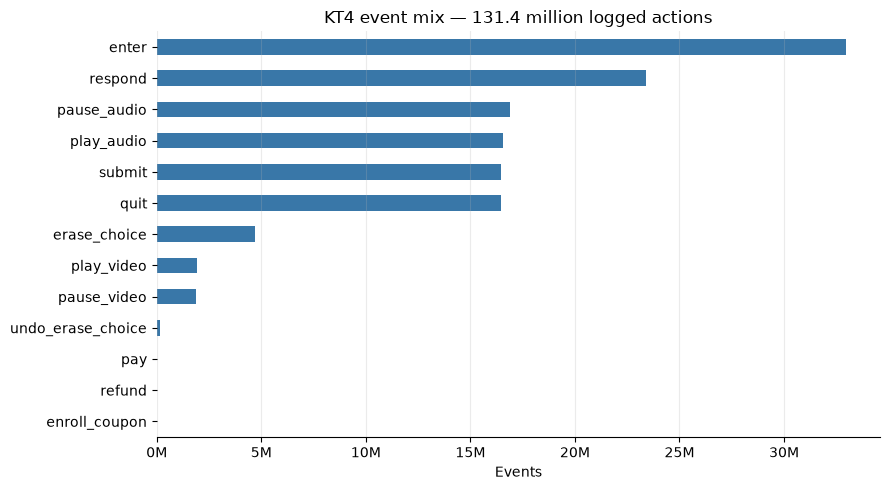

In [4]:
from matplotlib.ticker import FuncFormatter

kt4_actions = pd.Series({
    "enter": 32_943_087,
    "respond": 23_384_480,
    "pause_audio": 16_879_046,
    "play_audio": 16_580_464,
    "submit": 16_488_061,
    "quit": 16_455_026,
    "erase_choice": 4_714_534,
    "play_video": 1_928_356,
    "pause_video": 1_898_080,
    "undo_erase_choice": 142_092,
    "pay": 26_583,
    "refund": 1_126,
    "enroll_coupon": 603,
}, name="events").sort_values()

ax = kt4_actions.plot.barh(figsize=(9, 5), color="#3977a8")
ax.set_title("KT4 event mix — 131.4 million logged actions")
ax.set_xlabel("Events")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value / 1_000_000:.0f}M"))
ax.grid(axis="x", alpha=0.25)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()
plt.show()

### 3. Where did practice happen?

The most common KT2/KT3 `source` is `sprint`, where a learner chooses a TOEIC part to practice. Other sources include diagnosis, review, notes, and adaptive offers. About 70% of events were on mobile (KT2: **70.3%**, KT3: **71.1%**, KT4: **70.9%**). These source labels reveal product context; they are not randomized assignments, so differences between sources should not be read as causal effects.

In [5]:
source_counts = pd.DataFrame({
    "KT2": {
        "sprint": 40_018_192,
        "diagnosis": 6_623_563,
        "my_note": 3_901_232,
        "adaptive_offer": 2_726_362,
        "review_quiz": 2_235_537,
        "tutor": 480_846,
        "review": 374_870,
    },
    "KT3": {
        "sprint": 64_679_400,
        "diagnosis": 6_623_615,
        "my_note": 7_033_452,
        "adaptive_offer": 5_124_058,
        "review_quiz": 3_625_193,
        "tutor": 723_128,
        "review": 806_584,
        "archive": 655_224,
    },
}).fillna(0).astype("int64")

source_counts["KT2_share_%"] = (source_counts["KT2"] / 56_360_602 * 100).round(1)
source_counts["KT3_share_%"] = (source_counts["KT3"] / 89_270_654 * 100).round(1)
source_counts.sort_values("KT3", ascending=False)

,KT2,KT3,KT2_share_%,KT3_share_%
sprint,40018192,64679400,71.0,72.5
my_note,3901232,7033452,6.9,7.9
diagnosis,6623563,6623615,11.8,7.4
adaptive_offer,2726362,5124058,4.8,5.7
review_quiz,2235537,3625193,4.0,4.1
review,374870,806584,0.7,0.9
tutor,480846,723128,0.9,0.8
archive,0,655224,0.0,0.7


In [6]:
platform_counts = pd.DataFrame([
    {"tier": "KT2", "platform": "mobile", "events": 39_622_254},
    {"tier": "KT2", "platform": "web", "events": 16_738_348},
    {"tier": "KT3", "platform": "mobile", "events": 63_514_718},
    {"tier": "KT3", "platform": "web", "events": 25_755_936},
])
platform_counts["share_%"] = platform_counts.groupby("tier")["events"].transform(
    lambda values: values / values.sum() * 100
).round(1)
platform_counts

,tier,platform,events,share_%
0,KT2,mobile,39622254,70.3
1,KT2,web,16738348,29.7
2,KT3,mobile,63514718,71.1
3,KT3,web,25755936,28.9


### 4. What does the content catalog provide?

The question catalog provides question ID, bundle, answer key, TOEIC part, numeric skill tags, and deployment timestamp. The lecture catalog provides part, numeric tag, video length, and deployment timestamp. The supplied archive does not contain readable question or lesson text, and tag IDs have no accompanying names.

In [7]:
with ZipFile(contents_zip_path) as archive:
    lecture_info = pd.read_csv(archive.open("contents/lectures.csv"))
    payment_info = pd.read_csv(archive.open("contents/payments.csv"))
    coupon_info = pd.read_csv(archive.open("contents/coupons.csv"))

contents_inventory = pd.DataFrame({
    "rows": {
        "questions": len(question_info),
        "lectures": len(lecture_info),
        "payments": len(payment_info),
        "coupons": len(coupon_info),
    }
})
contents_inventory

,rows
questions,13169
lectures,1021
payments,190
coupons,91


In [8]:
lecture_profile = lecture_info.assign(
    tag_available=lecture_info["tags"] != -1,
    length_available=lecture_info["video_length"] != -1,
    video_minutes=lecture_info["video_length"].where(
        lecture_info["video_length"] >= 0
    ) / 60_000,
).groupby("part").agg(
    lectures=("lecture_id", "size"),
    tagged=("tag_available", "sum"),
    known_lengths=("length_available", "sum"),
    median_video_minutes=("video_minutes", "median"),
).round(1)

lecture_profile

,lectures,tagged,known_lengths,median_video_minutes
part,,,,
-1,437,0,0,NaN
0,35,35,35,4.4
1,60,60,40,3.6
2,90,90,87,2.8
3,30,30,30,6.0
4,41,41,41,4.3
5,187,187,181,3.6
6,98,98,92,3.8
7,43,43,35,5.4


In [9]:
question_tags = (
    question_info.assign(tag=question_info["tags"].astype("string").str.split(";"))
    .explode("tag")
    .dropna(subset=["tag"])
)

unknown_question_tags = int((question_tags["tag"] == "-1").sum())
question_tags = question_tags[question_tags["tag"] != "-1"]

tag_question_counts = (
    question_tags.groupby("tag")["question_id"]
    .nunique()
    .sort_values(ascending=False)
)

lecture_tag_ids = set(
    lecture_info.loc[lecture_info["tags"] != -1, "tags"].astype("string")
)
all_catalog_tag_ids = set(tag_question_counts.index) | lecture_tag_ids

print("Distinct question tag IDs (excluding -1):", tag_question_counts.size)
print("Distinct lecture tag IDs:", len(lecture_tag_ids))
print("Distinct tag IDs across questions and lectures:", len(all_catalog_tag_ids))
print("Question tag sentinel occurrences (-1):", unknown_question_tags)
tag_question_counts.head(15).rename("questions").to_frame()

Distinct question tag IDs (excluding -1): 188
Distinct lecture tag IDs: 259
Distinct tag IDs across questions and lectures: 293
Question tag sentinel occurrences (-1): 797


,questions
tag,
183,1997
181,1886
182,1723
184,1360
179,918
185,796
74,731
52,713
24,712


The catalog has 1,021 lectures. **453** have an unknown deployment time, and **437** have `part == -1`; the sentinel also appears for unavailable tags and video lengths. Question tags contain `-1` entries too, so the tag-frequency table excludes that sentinel. Tags are numeric IDs without names in the supplied files. The payment table’s actual duration column is misspelled `duaration`. Payment and coupon events describe access or promotion, not learning progress. EdNet’s README says score data were not released.

## EDA findings and planner fit

### What the KT1 results show

- The typical student has a short history: median **10 distinct questions**; 75% have answered **37 or fewer**. **24.3%** of students answered at least one question ID more than once.
- Across **95.27 million nonblank answers**, **65.3%** were correct. Accuracy varies by part (Part 1 **73.8%**, Part 5 **60.4%**); these are descriptive rates, not proof that a part caused better or worse learning.
- **885 of 13,169 catalog questions (6.7%)** had no responses. Response exposure is highly uneven: the median question received **4,627** responses, while the most-answered received **241,688**.
- Bundle question counts are tightly aligned: **99.4%** of answered bundles have question counts within 1% of each other. This supports treating the bundle as a practice unit.
- Response-time values are not safe as direct study-duration labels. Most fall between 5 seconds and 2 minutes, but the archive has **21,558** values over 10 minutes; the largest inspected records are about **18–79 hours**. The same extreme value can repeat across questions in a bundle.

### Decision

**Good fit:** an adaptive TOEIC practice component that selects question bundles using a learner’s earlier correctness and practice history. KT2–KT4 also support behavioral analyses of tentative answers, review, explanations, and media use. A useful model target is correctness on a future question; evaluate with student-held-out and time-respecting splits.

**Not a fit by itself:** a general planner for arbitrary classes, assignments, deadlines, and calendars. EdNet has no user availability, course deadlines, assignment workload, or measured learning-gain outcome. Use it as a TOEIC-specific module only; collect the planner’s schedule and goals from the user or use a separate course/assessment dataset.

### Important limits

- Sparse histories mean cold-start predictions need a diagnostic set or population baseline.
- Numeric tags are not human-readable skill names, and the supplied archive has IDs and answer keys rather than question/lesson text.
- Observed recommendations and actions are subject to selection bias; they cannot establish that a recommendation caused improvement.
- The timestamps are shifted for privacy, so use within-learner order and relative gaps, not real calendar dates.
- The release is under **CC BY-NC 4.0**; resolve permissions before any commercial use. See the [official EdNet README](https://github.com/riiid/ednet/blob/master/README.md).